# Fase 5. Calidad de datos y línea base
**Gobernanza de IA en Operaciones: KPI, ROI y control de procesos con Power BI**
Caso: Materiales Cumbre Andina (empresa ficticia, datos sintéticos).

Este notebook muestra el análisis paso a paso. Cada paso explica primero **por qué** se hace y después **cómo**.

| | |
|---|---|
| Qué recibe | 12 meses de histórico del proceso manual (oct 2025 a sep 2026) |
| Qué hace | Diagnostica, corrige con reglas escritas, valida contra los valores correctos y calcula los KPI del antes |
| Qué entrega | `datos/limpio/` y los KPI mensuales para Power BI |

In [1]:
import re, difflib, subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path('..').resolve()
H, L, V = RAIZ/'datos'/'historico', RAIZ/'datos'/'limpio', RAIZ/'datos'/'verdad'
leer = lambda carpeta, n: pd.read_csv(carpeta/n, dtype=str, encoding='utf-8-sig')
f, p = leer(H, 'facturas_historico.csv'), leer(H, 'proveedores.csv')
r, c = leer(H, 'reclamos_historico.csv'), leer(H, 'clientes.csv')
print(f'Facturas: {len(f):,} | Reclamos: {len(r):,} | Clientes: {len(c):,} | Proveedores: {len(p)}')

Facturas: 11,124 | Reclamos: 4,200 | Clientes: 8,000 | Proveedores: 120


## Paso 1. Diagnóstico
**Por qué:** antes de limpiar hay que medir qué está mal. Si no, no se puede explicar qué se corrigió ni cuánto le costaba a la empresa.
Regla: el diagnóstico se hace **sin mirar la carpeta `verdad`**, como en una empresa real.

In [2]:
def cuit_valido(x):
    d = re.sub(r'\D', '', str(x))
    if len(d) != 11:
        return False
    s = sum(int(a) * b for a, b in zip(d[:10], [5, 4, 3, 2, 7, 6, 5, 4, 3, 2]))
    v = 11 - s % 11
    return {11: 0, 10: 9}.get(v, v) == int(d[10])

maestro = p.set_index('proveedor_id')
neto, iva, total = (pd.to_numeric(f[x]) for x in ['neto', 'iva', 'total'])
clave = ['proveedor_id', 'punto_venta', 'numero', 'tipo_comprobante']
diagnostico = pd.Series({
    'Duplicadas (pares)': f.duplicated(clave).sum(),
    'Razón social distinta al maestro': (f['razon_social'] != f['proveedor_id'].map(maestro['razon_social'])).sum(),
    'Fecha en otro formato': (~f['fecha_emision'].str.fullmatch(r'\d{4}-\d{2}-\d{2}')).sum(),
    'CUIT inválido': (~f['cuit_emisor'].map(cuit_valido)).sum(),
    'Total que no cierra': ((neto + iva - total).abs() > 0.05).sum(),
    'IVA que no cierra': ((neto * pd.to_numeric(f['alicuota_iva']) - iva).abs() > 0.05).sum(),
    'DNI repetido en clientes': c['dni'].duplicated(keep=False).sum(),
}, name='casos')
diagnostico.to_frame()

,casos
Duplicadas (pares),324
Razón social distinta al maestro,570
Fecha en otro formato,457
CUIT inválido,241
Total que no cierra,208
IVA que no cierra,0
DNI repetido en clientes,2


**Lectura:** el IVA siempre cierra, así que cuando el total no cierra el campo equivocado es el total. El DNI repetido no estaba sembrado: apareció por azar y el diagnóstico lo encontró.

## Paso 2 y 3. Reglas de corrección y aplicación
**Por qué:** limpiar no es borrar ni pisar. Cada corrección deja el valor original, el corregido y una marca. Así cualquiera puede auditar qué se hizo.

| # | Problema | Regla |
|---|---|---|
| 1 | Fecha en otro formato | aaaa-mm-dd, día primero, año de 2 dígitos = 20aa; si no es coherente con la recepción, a revisión |
| 2 | CUIT inválido | se toma el del maestro por proveedor_id |
| 3 | Razón social distinta | la del maestro si se parece 80% o más; si no, a revisión |
| 4 | Total que no cierra | para analizar, neto + IVA; en la realidad es excepción para revisión |
| 5 | Duplicadas | no se borran: se marca la copia, su original y si el proceso manual la detectó |
| 6 | DNI repetido | no se corrige: se marcan ambos clientes |

Las reglas están en `scripts/limpiar_historico.py`. Se ejecuta acá para que el notebook sea reproducible.

In [3]:
print(subprocess.run([sys.executable, str(RAIZ/'scripts'/'limpiar_historico.py')], capture_output=True, text=True).stdout)
fl = pd.read_csv(L/'facturas_limpio.csv', encoding='utf-8-sig')
fl[fl['cuit_corregido'] | fl['fecha_normalizada']][['factura_id', 'fecha_emision_original', 'fecha_emision', 'cuit_original', 'cuit_emisor']].head()

{'fecha_normalizada': 457, 'revisar_fecha': 0, 'cuit_corregido': 241, 'razon_estandarizada': 570, 'revisar_razon': 0, 'excepcion_monto': 208, 'es_duplicada': 324} | duplicadas no detectadas: 187 | clientes a revisar: 2



,factura_id,fecha_emision_original,fecha_emision,cuit_original,cuit_emisor
8,F-000009,02.10.2025,2025-10-02,30-61024831-0,30-61024831-0
9,F-000010,17-10-25,2025-10-17,33-71570529-5,33-71570529-5
22,F-000023,10.10.2025,2025-10-10,30-61582079-9,30-61582079-9
39,F-000040,2025-10-13,2025-10-13,30-52529497-5,30-52529497-4
51,F-000052,2025-10-14,2025-10-14,33-62146585-3,33-62146585-1


## Paso 3b. Validación contra los valores correctos
**Por qué:** una limpieza vale por cuánto acierta. Recién ahora se usa la carpeta `verdad`.

In [4]:
vf = pd.read_csv(V/'facturas_historico_verdad.csv', encoding='utf-8-sig')
m = fl.merge(vf, on='factura_id', suffixes=('', '_verdad'))
err = m['error_sembrado'].fillna('')
filas = []
for marca, sembrado, ok in [
    ('fecha_normalizada', 'fecha_otro_formato', m['fecha_emision'] == m['fecha_emision_correcta']),
    ('cuit_corregido', 'cuit_invalido', m['cuit_emisor'] == m['cuit_correcto']),
    ('razon_estandarizada', 'razon_social_distinta', m['razon_social'] == m['razon_social_correcta']),
    ('excepcion_monto', 'monto_no_cierra', (m['total'] - m['total_correcto']).abs() < 0.05),
]:
    filas.append({'regla': marca, 'marcadas': int(m[marca].sum()), 'sembradas': int(err.str.contains(sembrado).sum()),
                  'sin detectar': int((err.str.contains(sembrado) & ~m[marca]).sum()),
                  'valor final correcto': f"{ok.mean():.0%}"})
dup_ok = (m['es_duplicada'] == m['es_duplicada_verdad'].astype(bool)).mean()
filas.append({'regla': 'es_duplicada', 'marcadas': int(m['es_duplicada'].sum()),
              'sembradas': int(m['es_duplicada_verdad'].astype(bool).sum()), 'sin detectar': 0,
              'valor final correcto': f'{dup_ok:.0%}'})
pd.DataFrame(filas)

,regla,marcadas,sembradas,sin detectar,valor final correcto
0,fecha_normalizada,457,446,0,100%
1,cuit_corregido,241,228,0,100%
2,razon_estandarizada,570,555,0,100%
3,excepcion_monto,208,201,0,100%
4,es_duplicada,324,324,0,100%


**Por qué hay más marcadas que sembradas:** las duplicadas son copias. Si la original tenía un error, la copia también, y la limpieza lo corrige. El archivo de verdad etiqueta esas copias solo como "duplicada".

**Límite:** el 100% es alto porque los errores los sembró el propio proyecto. Con datos reales aparecen errores no previstos: para eso están las marcas "revisar" y la cola de revisión humana.

## Paso 4. Línea base: KPI del antes
**Por qué:** sin el "antes", ninguna mejora se puede demostrar.
Supuestos: día hábil = lunes a viernes de 8 a 17, sin feriados; el mes de cada factura es el de su emisión; "área equivocada" se mide por auditoría (archivo de verdad).

In [5]:
print(subprocess.run([sys.executable, str(RAIZ/'scripts'/'linea_base.py')], capture_output=True, text=True).returncode == 0)
kf = pd.read_csv(L/'kpi_linea_base_facturas.csv', encoding='utf-8-sig', index_col='mes')
kr = pd.read_csv(L/'kpi_linea_base_reclamos.csv', encoding='utf-8-sig', index_col='mes')
t, tr = kf.loc['TOTAL 12 meses'], kr.loc['TOTAL 12 meses']
ar = lambda txt: txt.replace(',', 'X').replace('.', ',').replace('X', '.')  # formato argentino
tabla = pd.DataFrame([
    ('¿Cuánto tarda una factura en quedar cargada?', f"{t.dias_hasta_quedar_cargada:.1f} días hábiles"),
    ('Facturas cargadas tarde (más de 2 días hábiles)', f"{t.pct_cargadas_tarde:.0f}%"),
    ('Horas por mes cargando facturas a mano', f"{t.horas_cargando_a_mano/12:.0f}"),
    ('Facturas con algún dato mal', f"{t.pct_con_algun_dato_mal:.1f}%"),
    ('Facturas pagadas dos veces', f"{t.pagadas_dos_veces:.0f} (${t.pesos_pagados_dos_veces/1e6:,.1f} M)"),
    ('¿Cuánto espera un cliente la primera respuesta?', f"{tr.horas_hasta_primera_respuesta:.1f} horas hábiles"),
    ('Clientes que esperan más de un día', f"{tr.pct_esperan_mas_de_un_dia:.1f}%"),
    ('Reclamos resueltos a tiempo', f"{tr.pct_resueltos_a_tiempo:.0f}%"),
    ('Reclamos enviados al área equivocada', f"{tr.pct_area_equivocada:.0f}%"),
    ('Reclamos que vuelven a abrirse', f"{tr.pct_vuelven_a_abrirse:.1f}%"),
], columns=['KPI', 'Antes (12 meses)'])
tabla['Antes (12 meses)'] = tabla['Antes (12 meses)'].map(ar)
tabla

True


,KPI,Antes (12 meses)
0,¿Cuánto tarda una factura en quedar cargada?,"2,7 días hábiles"
1,Facturas cargadas tarde (más de 2 días hábiles),46%
2,Horas por mes cargando facturas a mano,142
3,Facturas con algún dato mal,"12,8%"
4,Facturas pagadas dos veces,"166 ($168,8 M)"
5,¿Cuánto espera un cliente la primera respuesta?,"16,8 horas hábiles"
6,Clientes que esperan más de un día,"21,5%"
7,Reclamos resueltos a tiempo,80%
8,Reclamos enviados al área equivocada,15%
9,Reclamos que vuelven a abrirse,"7,7%"


## Gráficos
Colores: azul y naranja de una paleta validada para daltonismo. Sin doble eje.

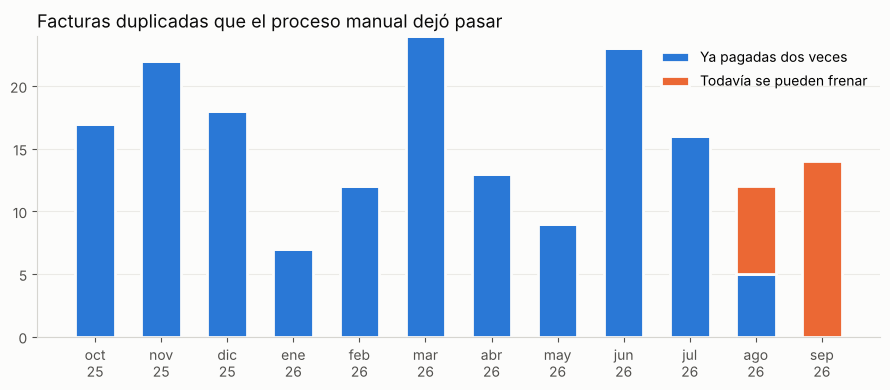

In [6]:
AZUL, NARANJA, TINTA, TINTA2, FONDO = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#fcfcfb'
plt.rcParams.update({'figure.facecolor': FONDO, 'axes.facecolor': FONDO, 'axes.edgecolor': '#d6d5d0',
                     'axes.labelcolor': TINTA2, 'xtick.color': TINTA2, 'ytick.color': TINTA2,
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
NOMBRE_MES = ['ene', 'feb', 'mar', 'abr', 'may', 'jun', 'jul', 'ago', 'sep', 'oct', 'nov', 'dic']
mensual = kf.drop('TOTAL 12 meses')
etiquetas = [f"{NOMBRE_MES[int(x[5:])-1]}\n{x[2:4]}" for x in mensual.index]

# 1. Facturas pagadas dos veces, por mes: ya pagadas vs todavía se pueden frenar
pagadas = mensual['pagadas_dos_veces']
pendientes = mensual['duplicadas_escapadas'] - pagadas
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(etiquetas, pagadas, color=AZUL, width=0.6, label='Ya pagadas dos veces', edgecolor=FONDO, linewidth=2)
ax.bar(etiquetas, pendientes, bottom=pagadas, color=NARANJA, width=0.6, label='Todavía se pueden frenar', edgecolor=FONDO, linewidth=2)
ax.set_title('Facturas duplicadas que el proceso manual dejó pasar', loc='left', color=TINTA, fontsize=13)
ax.grid(axis='y', color='#ebeae6'); ax.set_axisbelow(True); ax.legend(frameon=False, loc='upper right')
plt.tight_layout(); plt.show()

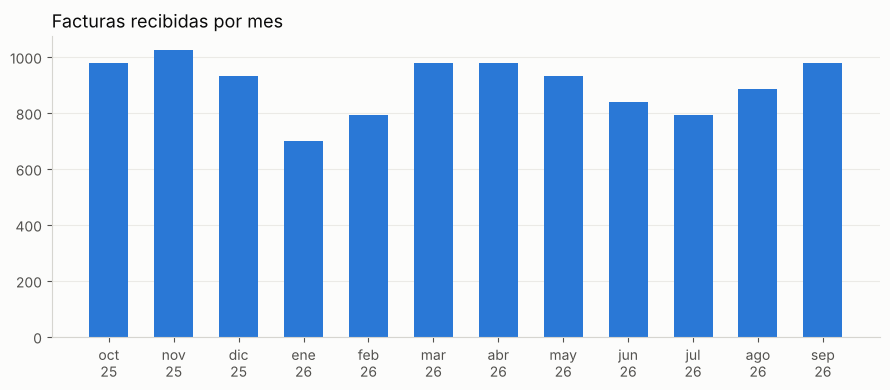

In [7]:
# 2. Volumen de facturas por mes (la temporada alta se ve acá)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(etiquetas, mensual['facturas_recibidas'], color=AZUL, width=0.6)
ax.set_title('Facturas recibidas por mes', loc='left', color=TINTA, fontsize=13)
ax.grid(axis='y', color='#ebeae6'); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

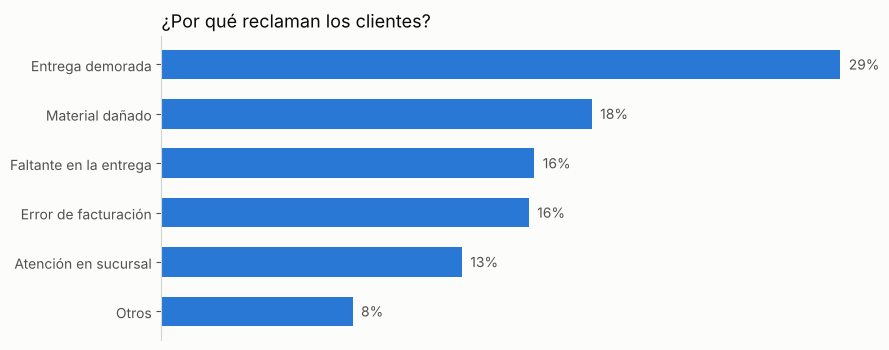

In [8]:
# 3. ¿Por qué reclaman?
motivos = pd.read_csv(L/'kpi_linea_base_reclamos_donde_y_por_que.csv', encoding='utf-8-sig').groupby('categoria_asignada')['reclamos'].sum().sort_values()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(motivos.index, motivos.values, color=AZUL, height=0.6)
for y, v in enumerate(motivos.values):
    ax.text(v + 15, y, f"{v/motivos.sum():.0%}", va='center', color=TINTA2)
ax.set_title('¿Por qué reclaman los clientes?', loc='left', color=TINTA, fontsize=13)
ax.spines['bottom'].set_visible(False); ax.set_xticks([])
plt.tight_layout(); plt.show()

## Lecturas y límites
1. **La temporada alta se ve en el volumen, no en los porcentajes.** El generador no modeló que el equipo empeore con más carga; en datos reales sería lo primero a investigar.
2. **Septiembre muestra 0 pagadas dos veces porque todavía no se pagaron**, no porque el proceso haya mejorado: son las que aún se pueden frenar.
3. **Las horas todavía no son plata.** El costo por hora es un supuesto que se define en la Fase 10.